In [1]:
import keras

In [8]:
import warnings
warnings.filterwarnings('ignore')

In [9]:
mnist = keras.datasets.mnist
(Xtrain, ytrain), (Xtest, ytest) = mnist.load_data()

In [10]:
Xtrain.shape

(60000, 28, 28)

In [11]:
Xtest.dtype

dtype('uint8')

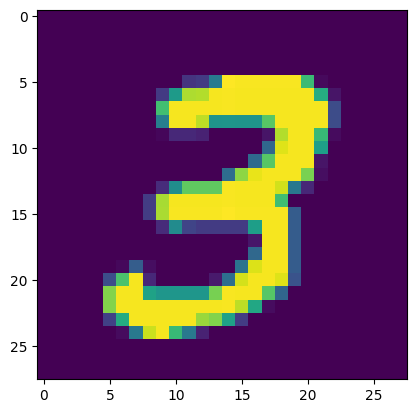

In [13]:
import matplotlib.pyplot as plt
plt.imshow(Xtrain[7])

> [ NOTE ]: `Since we are going to train neural network, we must scale the input features`

*For simplicity, we’ll scale the pixel intensities down to the 0–1 range by dividing them by 255.0*

In [14]:
Xtrain = Xtrain / 255.0
Xtest = Xtest / 255.0

In [16]:
# Xtrain[0]

In [18]:
ytrain

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [19]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape = [28, 28]),
    keras.layers.Dense(200, activation = 'relu'),
    keras.layers.Dense(100, activation = 'relu'),
    keras.layers.Dense(10, activation = 'softmax')
])

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,110 (695.74 KB)

 Trainable params: 178,110 (695.74 KB)

 Non-trainable params: 0 (0.00 B)

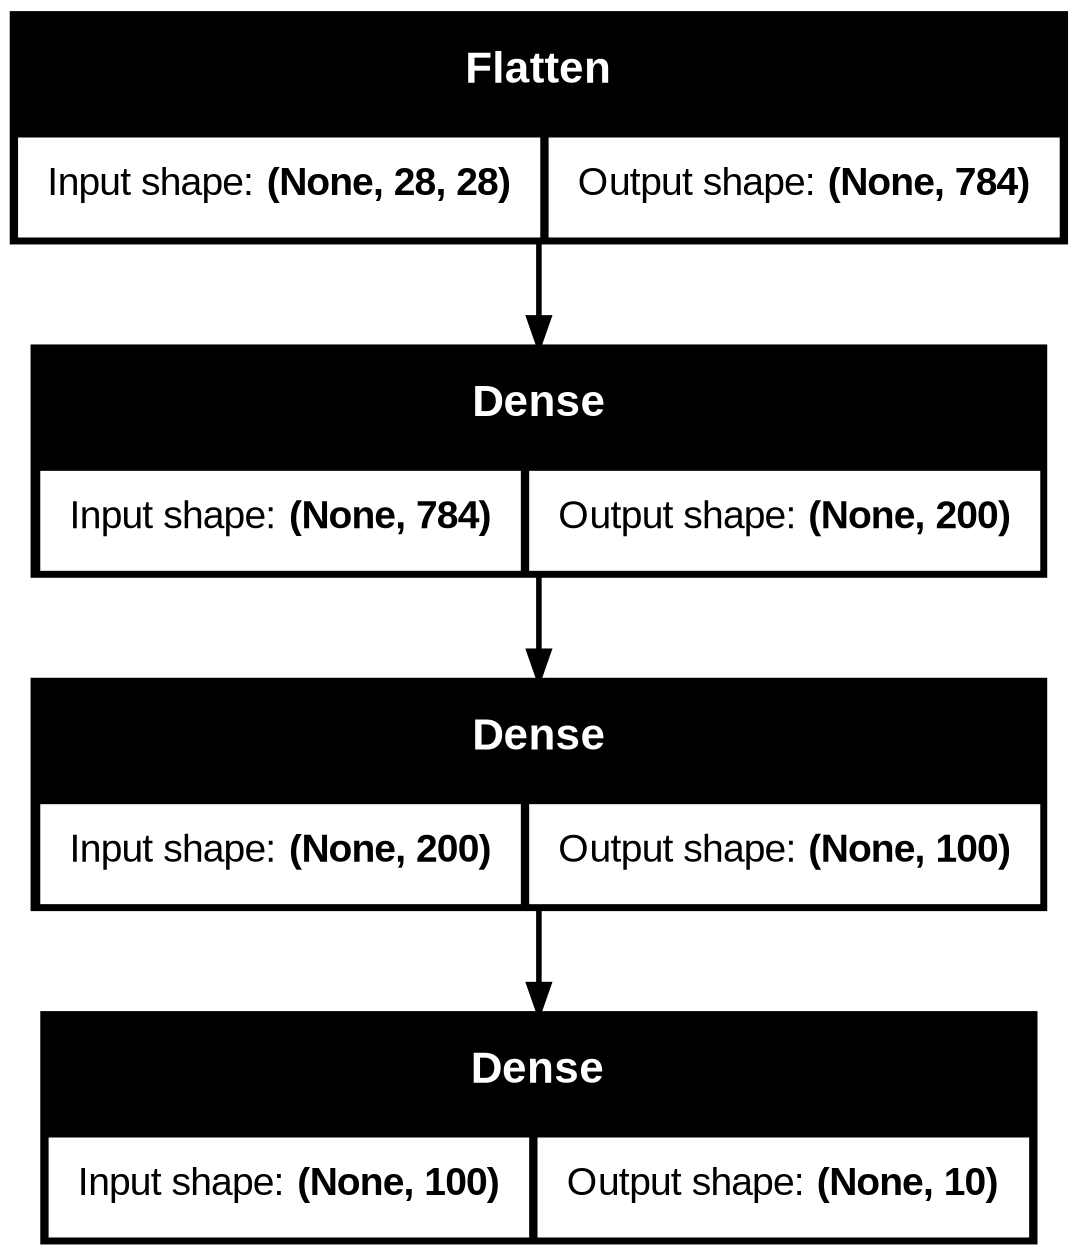

In [21]:
keras.utils.plot_model(model, show_shapes=True)

In [22]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [23]:
hidden1 = model.layers[1]
hidden1

<Dense name=dense, built=True>

In [25]:
model.get_layer('dense') is hidden1

True

In [31]:
weights, bias = hidden1.get_weights()
print(weights.shape)
print(bias.shape)

(784, 200)
(200,)


In [32]:
weights

array([[-0.04737287, -0.02986573, -0.01379991, ...,  0.0182191 ,
         0.0459034 , -0.03504601],
       [ 0.02664307,  0.01788051, -0.06206677, ...,  0.0105885 ,
         0.03414099,  0.00620232],
       [-0.00877067, -0.01159549, -0.00093684, ..., -0.03897889,
        -0.00654949, -0.01667883],
       ...,
       [-0.04955994, -0.05929506,  0.02867903, ..., -0.04365692,
        -0.06786989,  0.05788721],
       [ 0.04736987,  0.00495885, -0.06662793, ..., -0.04943714,
        -0.06320815,  0.02810086],
       [-0.01380472,  0.05939326,  0.03024539, ...,  0.04391447,
        -0.04566504, -0.00111898]], shape=(784, 200), dtype=float32)

In [33]:
bias

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [35]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [36]:
history = model.fit(
    Xtrain, ytrain,
    validation_split = 0.2,
    epochs = 30
)

Epoch 1/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9285 - loss: 0.2406 - val_accuracy: 0.9640 - val_loss: 0.1232
Epoch 2/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9700 - loss: 0.0980 - val_accuracy: 0.9625 - val_loss: 0.1263
Epoch 3/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9788 - loss: 0.0672 - val_accuracy: 0.9745 - val_loss: 0.0911
Epoch 4/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9847 - loss: 0.0478 - val_accuracy: 0.9690 - val_loss: 0.1148
Epoch 5/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9886 - loss: 0.0357 - val_accuracy: 0.9747 - val_loss: 0.0940
Epoch 6/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9902 - loss: 0.0301 - val_accuracy: 0.9713 - val_loss: 0.1194
Epoch 7/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9913 - loss: 0.0259 - val_accuracy: 0.9775 - val_loss: 0.0909
Epoch 8/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9932 - loss: 0.0198 - 

In [37]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 1500}

In [38]:
history.epoch

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]

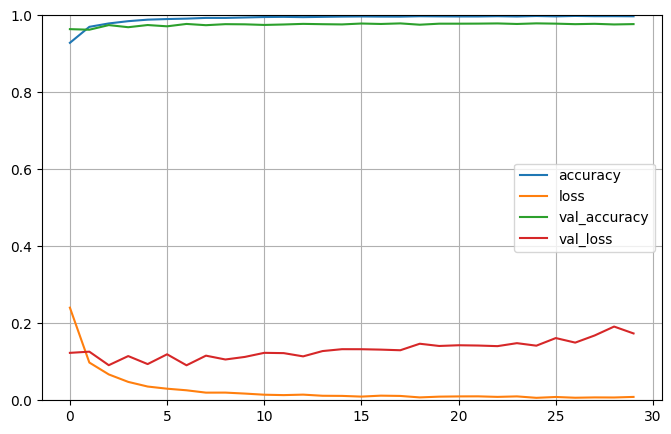

In [40]:
import pandas as pd

pd.DataFrame(history.history).plot(figsize = (8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1) # Set the vertical range [0-1]

plt.show()

In [41]:
model.evaluate(Xtest, ytest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9804 - loss: 0.1284


[0.12835870683193207, 0.980400025844574]

In [44]:
Xnew = Xtest[:3]
ypred = model.predict(Xnew).argmax(axis = 1)
ypred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


array([7, 2, 1])

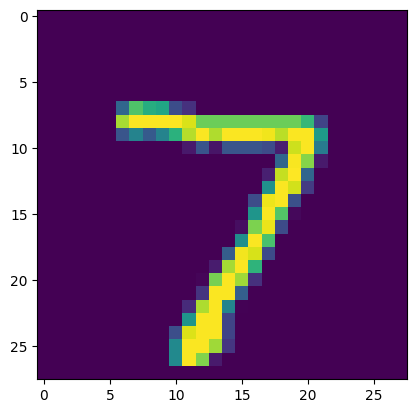

In [50]:
plt.imshow(Xnew[0])

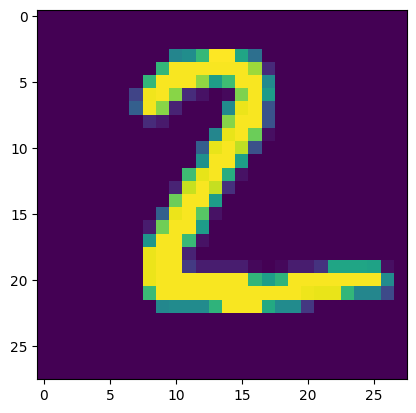

In [56]:
plt.imshow(Xnew[1])

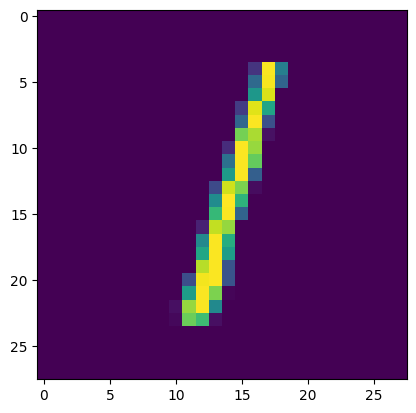

In [57]:
plt.imshow(Xnew[2])